# S3b — Conditional GAN (course version)

**Goal:** learn $p(x \mid y)$ with a conditional GAN, using exactly what the GAN course teaches, and compare it with the CVAE of S3a.

| Part | Choice | Course |
|---|---|---|
| Generator $G(z, y)$ | $[z, \text{embedding}(y)]$ → transposed convs, BatchNorm, ReLU, `tanh` (**same architecture as the CVAE decoder**) | slides 19–20, 23 |
| Discriminator $D(x, y)$ | image + one-hot class maps → strided convs (no pooling), LeakyReLU(0.2), BatchNorm → probability "real and coherent with $y$" | slides 19–20, 23–24 |
| Loss of D | binary cross-entropy: real → 1, fake → 0 | slide 9 |
| Loss of G | **non-saturating**: maximise $\log D(G(z, y), y)$ | slide 10 |
| Training | alternate one step of D and one step of G, new noise for G | slides 12, 14 |
| Tricks | label smoothing (real target **0.9**), Adam lr **2e-4**, β1 **0.5**, data in [-1, 1], look at the images, not only at the losses | slide 18 |

**Settings:** `configs/cgan.yaml` — **100 epochs**, z of size 64, sqrt-balanced sampler.

> **Why 100 epochs and not 15:** a first run with 15 epochs (~760 training steps) had healthy dynamics (D(x) ≈ 0.48, D(G(z)) ≈ 0.42) but the images showed a grid (checkerboard) pattern, a purple tint and almost no class control. A GAN needs many more steps than a VAE to learn fine structure. 100 epochs is ~5 000 steps, about 20 minutes on a T4 GPU.
>
> Use a GPU (Colab). `QUICK = True` trains for 10 epochs.

In [27]:
# --- Setup: works locally (.venv) and with the VS Code Colab kernel, WITHOUT git ---
# The project code (src/, configs/) travels inside this cell. After changing code on the laptop, run:
#     python -m src.sync_code notebooks/03a_cvae.ipynb notebooks/03b_cgan.ipynb
# then run this notebook again.
CODE_ZIP = "..."

import os, sys, io, base64, zipfile, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules or Path("/content").exists()
if IN_COLAB:
    root = Path("/content/mini_project")
    root.mkdir(parents=True, exist_ok=True)
    zipfile.ZipFile(io.BytesIO(base64.b64decode(CODE_ZIP))).extractall(root)   # laptop code -> Colab
    os.chdir(root)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "medmnist", "pyyaml"], check=True)
    for name in [m for m in sys.modules if m == "src" or m.startswith("src.")]:
        del sys.modules[name]           # forget any older version of src already loaded in this kernel
elif Path.cwd().name == "notebooks":
    os.chdir("..")                      # local run: go to the repository root

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
print("Project root:", Path.cwd())

Project root: /content/mini_project


In [28]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.data import load_split, sample_per_class, NUM_CLASSES, SHORT_NAMES
from src.train_gen import train_cgan, generate, class_diversity
from src.viz import plot_grid, plot_class_grid
from src.utils import (load_config, get_device, ensure_dirs, lerp, slerp, save_half, export_results,
                       RESULTS_DIR, CKPT_DIR)

QUICK = False          # True = shorter run: 10 epochs

cfg = load_config("cgan")
if QUICK:
    cfg["train"].update(epochs=10)
N = cfg["sampling"]["n_per_class"]
Z_DIM = cfg["model"]["z_dim"]
ensure_dirs()
device = get_device()
print("device:", device, "| train config:", cfg["train"])

train_x, train_y = load_split("train", cfg["data"]["size"])
print("train", train_x.shape)

device: cuda | train config: {'epochs': 100, 'lr': 0.0002, 'beta1': 0.5, 'real_label': 0.9, 'class_power': 0.5, 'seed': 0}
train (7007, 64, 64, 3)


## 1. Training

In [29]:
G, D, history, grids = train_cgan(train_x, train_y, cfg, seed=cfg["train"]["seed"], device=device)

torch.save(G.state_dict(), CKPT_DIR / "cgan_G_full.pt")
torch.save(D.state_dict(), CKPT_DIR / "cgan_D_full.pt")
save_half(G.state_dict(), CKPT_DIR / "cgan_G.pt")             # generator used in S4 (float16)
with open(RESULTS_DIR / "s3_cgan_history.json", "w") as f:
    json.dump(history, f)
print("Generator saved: checkpoints/cgan_G.pt")

[cGAN] epoch  1/100 | loss_D 1.258 | loss_G 3.662 | D(x) 0.64 | D(G(z)) 0.27 | 13s
[cGAN] epoch  2/100 | loss_D 0.961 | loss_G 3.641 | D(x) 0.66 | D(G(z)) 0.23 | 13s
[cGAN] epoch  3/100 | loss_D 0.815 | loss_G 3.903 | D(x) 0.70 | D(G(z)) 0.20 | 12s
[cGAN] epoch  4/100 | loss_D 0.872 | loss_G 3.827 | D(x) 0.69 | D(G(z)) 0.20 | 12s
[cGAN] epoch  5/100 | loss_D 1.094 | loss_G 3.282 | D(x) 0.64 | D(G(z)) 0.26 | 12s
[cGAN] epoch  6/100 | loss_D 1.151 | loss_G 1.983 | D(x) 0.59 | D(G(z)) 0.32 | 12s
[cGAN] epoch  7/100 | loss_D 1.102 | loss_G 1.991 | D(x) 0.60 | D(G(z)) 0.29 | 12s
[cGAN] epoch  8/100 | loss_D 1.144 | loss_G 1.905 | D(x) 0.59 | D(G(z)) 0.32 | 12s
[cGAN] epoch  9/100 | loss_D 1.117 | loss_G 1.863 | D(x) 0.59 | D(G(z)) 0.31 | 12s
[cGAN] epoch 10/100 | loss_D 1.192 | loss_G 1.832 | D(x) 0.56 | D(G(z)) 0.34 | 12s
[cGAN] epoch 11/100 | loss_D 1.172 | loss_G 1.712 | D(x) 0.56 | D(G(z)) 0.34 | 12s
[cGAN] epoch 12/100 | loss_D 1.340 | loss_G 1.710 | D(x) 0.52 | D(G(z)) 0.38 | 12s
[cGA

## 2. Loss curves and discriminator outputs

GAN losses do not simply decrease: G and D play against each other (slide 11). We look for an **equilibrium**: losses that oscillate without exploding, and $D(x)$ above $D(G(z))$ without the gap becoming extreme. At the ideal equilibrium $D = 1/2$ everywhere. If $D(G(z)) \to 0$ and `loss_G` keeps rising, D is too strong and G receives no useful gradient (slide 17).

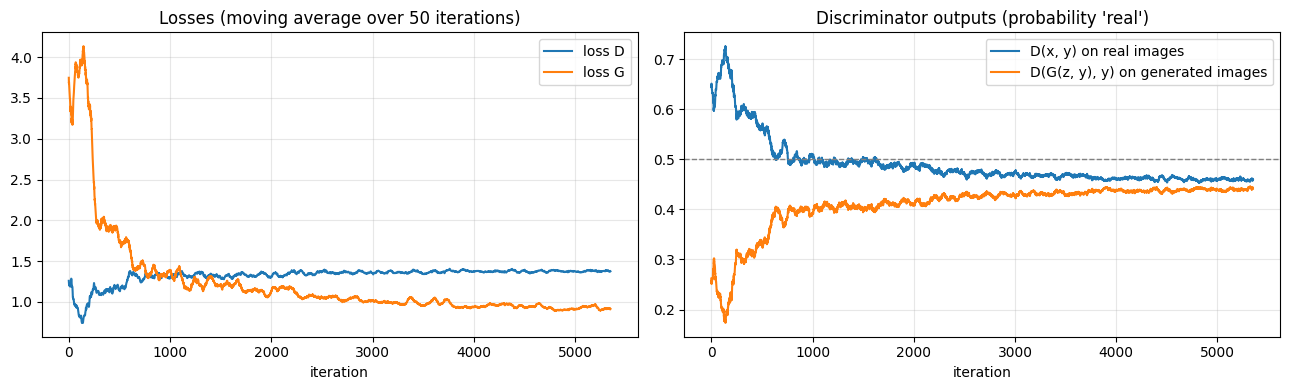

In [30]:
def smooth(v, k=50):
    v = np.asarray(v)
    return v if len(v) < k else np.convolve(v, np.ones(k) / k, mode="valid")


it = history["iters"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(smooth(it["loss_D"]), label="loss D")
axes[0].plot(smooth(it["loss_G"]), label="loss G")
axes[0].set_title("Losses (moving average over 50 iterations)")
axes[1].plot(smooth(it["D_real"]), label="D(x, y) on real images")
axes[1].plot(smooth(it["D_fake"]), label="D(G(z, y), y) on generated images")
axes[1].axhline(0.5, color="gray", ls="--", lw=1)
axes[1].set_title("Discriminator outputs (probability 'real')")
for ax in axes:
    ax.set_xlabel("iteration")
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "s3_cgan_losses.png", dpi=100, bbox_inches="tight")
plt.show()

## 3. Real vs synthetic images

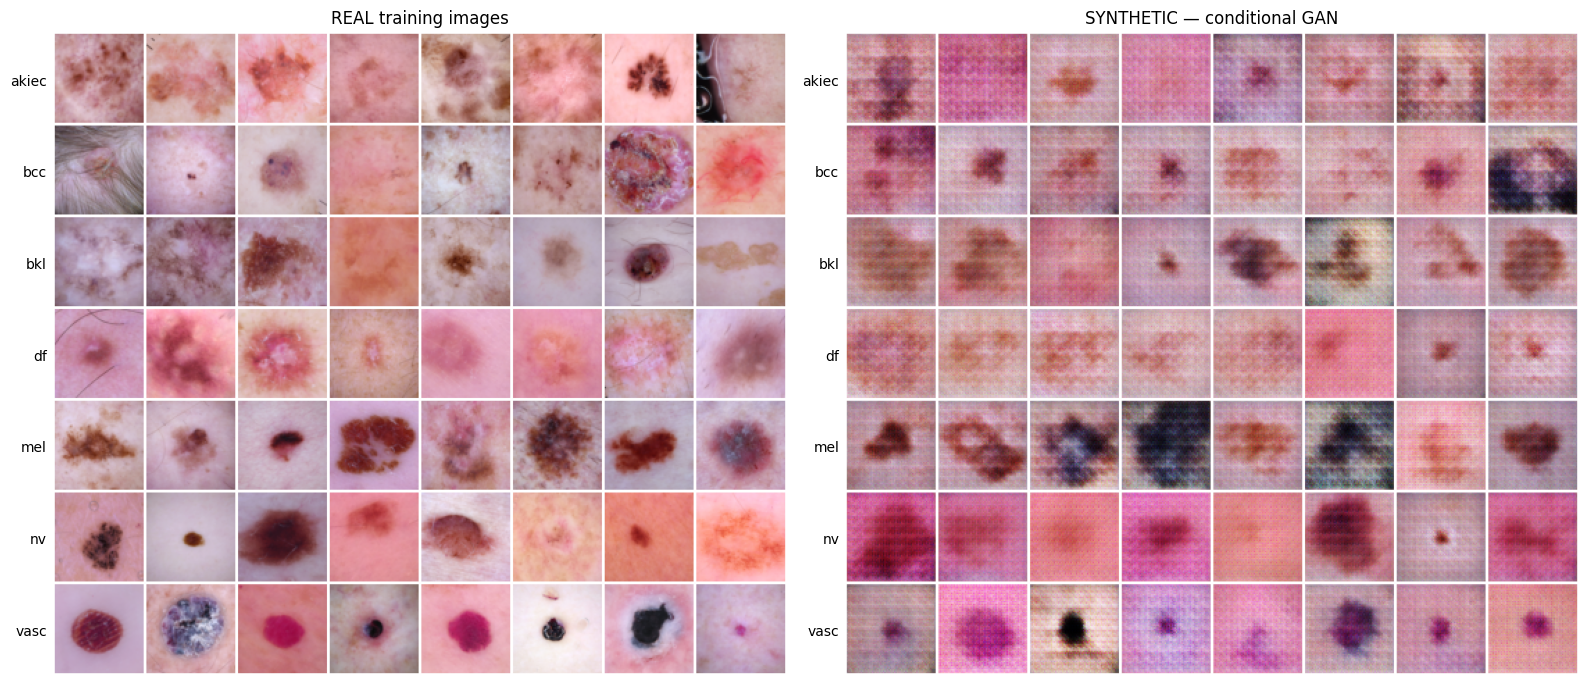

In [31]:
real, _ = sample_per_class(train_x, train_y, N, seed=0)
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
plot_class_grid(real, N, ax=axes[0], title="REAL training images")
plot_class_grid(grids[-1], N, ax=axes[1], title="SYNTHETIC — conditional GAN")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "s3_cgan_samples.png", dpi=100, bbox_inches="tight")
plt.show()

## 4. Evolution during training (same z and classes at every epoch)

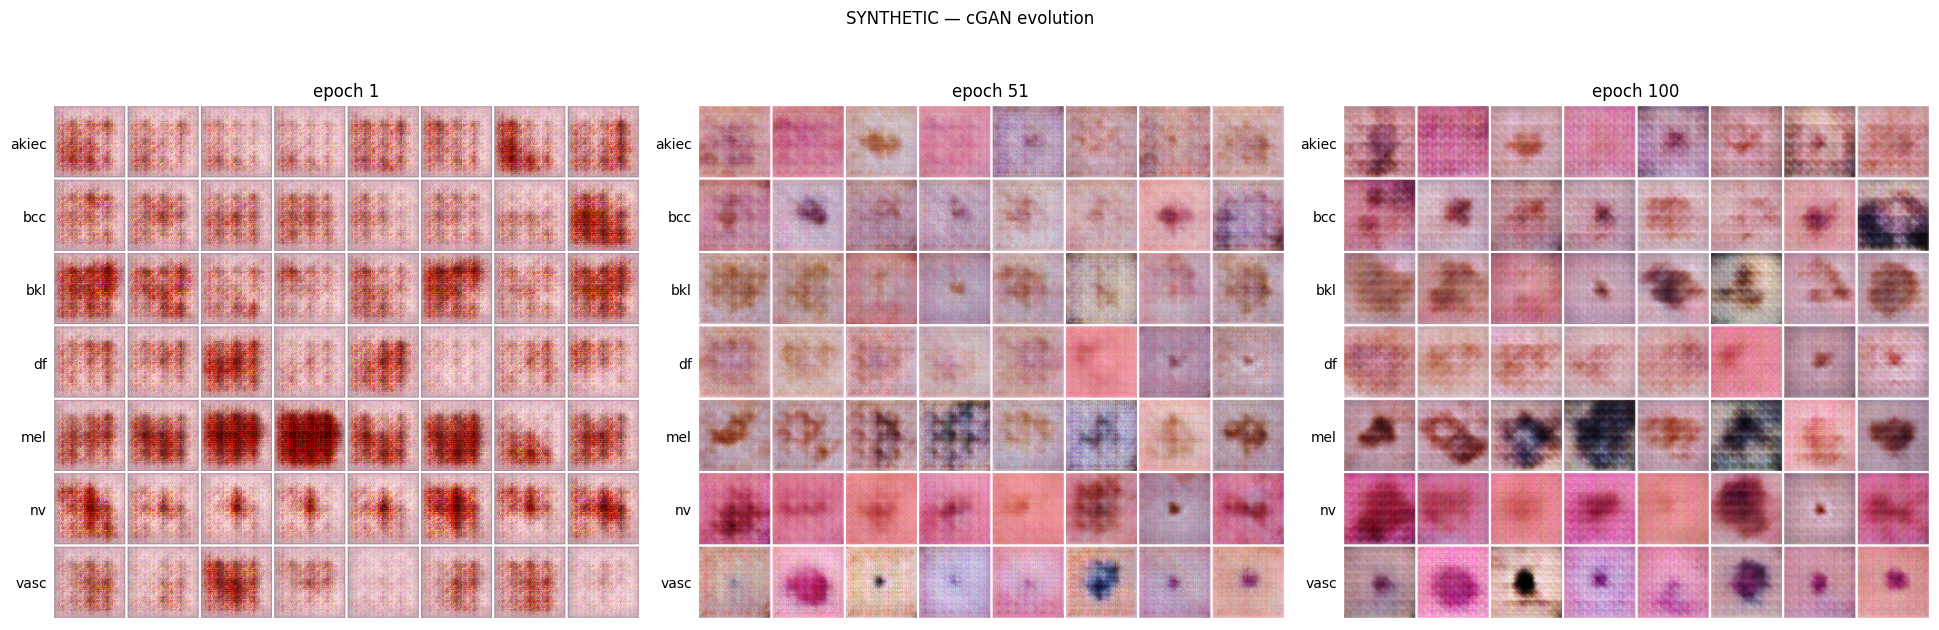

In [32]:
idx = sorted({0, len(grids) // 2, len(grids) - 1})
fig, axes = plt.subplots(1, len(idx), figsize=(6.5 * len(idx), 7))
for ax, i in zip(np.atleast_1d(axes), idx):
    plot_class_grid(grids[i], N, ax=ax, title=f"epoch {i + 1}")
fig.suptitle("SYNTHETIC — cGAN evolution")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "s3_cgan_evolution.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Mode collapse check: diversity per class

Mean pairwise distance between 64 generated images of a class, divided by the same measure on 64 real images. **Mode collapse** (slide 16) shows up as a ratio well below 1: the generator repeats almost the same image.

In [33]:
div = class_diversity(G, train_x, train_y, device)
div.to_csv(RESULTS_DIR / "s3_cgan_diversity.csv")
div

,real diversity,synthetic diversity,ratio
class,,,
akiec,33.16,32.81,0.99
bcc,32.47,30.74,0.95
bkl,35.41,37.23,1.05
df,33.27,29.91,0.90
mel,46.40,46.71,1.01
nv,40.47,43.45,1.07
vasc,41.25,44.63,1.08


## 6. Does the class really control the image? (class swap)

Same $z$ per row, a different class per column.

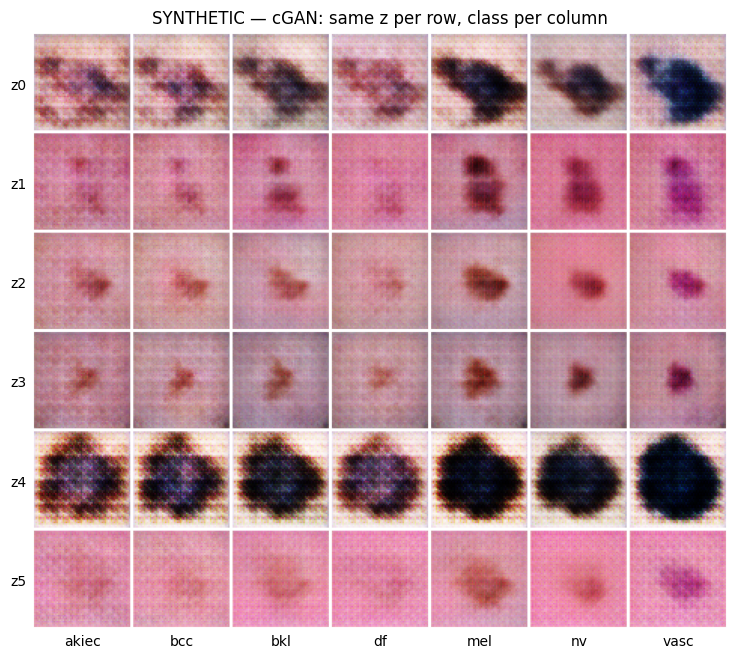

In [34]:
g = torch.Generator().manual_seed(1)
z = torch.randn(6, Z_DIM, generator=g).to(device)
zz = z.repeat_interleave(NUM_CLASSES, dim=0)
yy = torch.arange(NUM_CLASSES).repeat(6).to(device)
imgs = generate(G, yy, zz).cpu()
fig, ax = plt.subplots(figsize=(9, 8))
plot_grid(imgs, NUM_CLASSES, ax=ax, col_labels=SHORT_NAMES, row_labels=[f"z{i}" for i in range(6)],
          title="SYNTHETIC — cGAN: same z per row, class per column")
fig.savefig(RESULTS_DIR / "s3_cgan_class_swap.png", dpi=100, bbox_inches="tight")
plt.show()

## 7. Latent interpolation: linear vs spherical (slerp)

The GAN course (slide 21) recommends **slerp**: in high dimension, $\mathcal{N}(0, I)$ concentrates near a sphere, and the straight line between two codes passes through low-probability codes (smaller norm). For each class, the first row is linear, the second is slerp, between the same two codes.

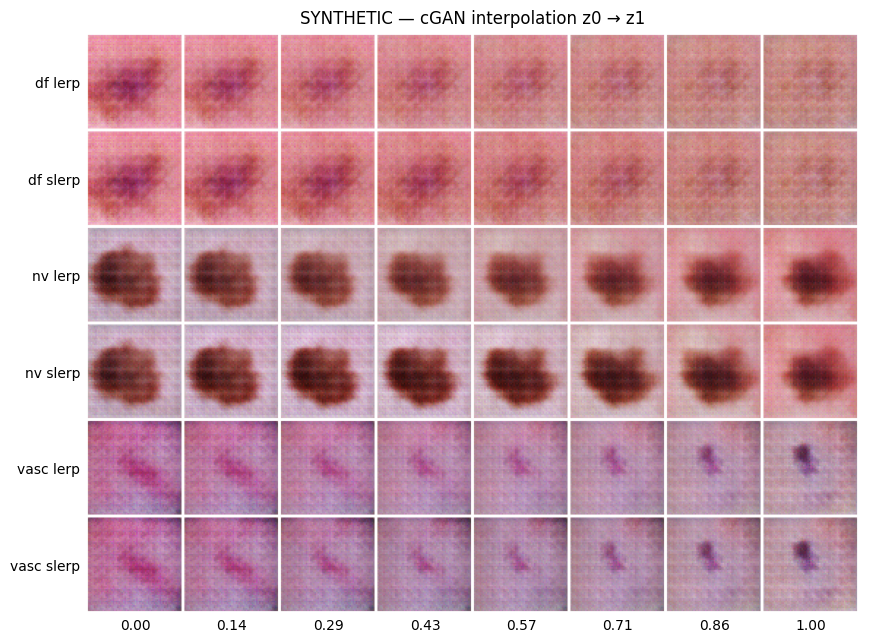

In [35]:
steps = 8
t = torch.linspace(0, 1, steps, device=device).view(-1, 1)
g = torch.Generator().manual_seed(2)
rows, labels = [], []
for c in [3, 5, 6]:                                   # df, nv, vasc
    z0, z1 = torch.randn(2, Z_DIM, generator=g).to(device).chunk(2)
    y = torch.full((steps,), c, device=device)
    rows += [generate(G, y, lerp(z0, z1, t)).cpu(), generate(G, y, slerp(z0, z1, t)).cpu()]
    labels += [f"{SHORT_NAMES[c]} lerp", f"{SHORT_NAMES[c]} slerp"]
fig, ax = plt.subplots(figsize=(10, 8))
plot_grid(torch.cat(rows), steps, ax=ax, row_labels=labels,
          col_labels=[f"{v:.2f}" for v in t.flatten().tolist()], title="SYNTHETIC — cGAN interpolation z0 → z1")
fig.savefig(RESULTS_DIR / "s3_cgan_interpolation.png", dpi=100, bbox_inches="tight")
plt.show()

## 8. Interpretation (to complete after running)

- **Training dynamics:** did the losses reach an equilibrium, or did D win (D(G(z)) → 0)?
- **Sharpness vs CVAE (H1):** are the cGAN images sharper than the CVAE images of S3a? Put the two `*_samples.png` figures side by side.
- **Diversity and mode collapse (H2):** compare the ratios with the CVAE table. Is **df** (80 training images) the most affected class?
- **Class swap:** does the lesion type follow the column?
- **Interpolation:** is slerp smoother than linear interpolation?
- **Memorization (H3)** is checked properly in S5 (nearest neighbours in the training set); for now, note whether some df samples look *identical* to real df images.

## Conclusion of S3b
- Generator: `checkpoints/cgan_G.pt` (float16), used in S4.
- Figures and tables: `results/s3_cgan_*`.
- Next: **S4**, generation of the synthetic sets.

## Export the results (Colab only)

On Colab the files are written on Google's machine. This cell zips the figures, the history and the main checkpoint (in float16, to keep it small):
- **browser Colab:** the zip is downloaded automatically (ignore the long text printed below it);
- **VS Code + Colab kernel:** the zip is printed as text. **Save the notebook (Ctrl+S)**, then run locally from the repository root:
  `python -m src.extract_results notebooks\03b_cgan.ipynb`

In [36]:
export_results(sorted(RESULTS_DIR.glob("s3_cgan_*")) + [CKPT_DIR / "cgan_G.pt"], "s3_cgan_results.zip")

[10573524 bytes extracted locally with src.extract_results: 8 files]
